# Reionization history: EOS26 vs EOS21, EOS16, Qin+25 and observations

Plots the volume-averaged neutral fraction $\overline{x}_{\rm HI}(z)$ of EOS26, EOS21 and EOS16 together with the
Qin et al. (2025) posterior (Ly$\alpha$ forest + UV LFs + $\tau_e$, their Fig. 4) and the observational constraints of
their Fig. 4, plus constraints published since.

Inputs
* **EOS26 fiducial**: box-mean $x_{\rm HI}$ at each node from the coeval logs (as in `EOS26_smallbox_xHI.ipynb`). While the
  production run is not finished, the 300 cMpc test box (HII_DIM = 200, same template and seed) is used below the lowest
  production redshift (the notebook prints a note for the caption). When the production logs reach z = 5 the test box
  is no longer used.
* **EOS26 early EoR**: the finished EOS26_earlyEoR production run, from `EOS26_earlyEoR_xHI.txt` (made from its coeval logs).
* **EOS21** (Muñoz et al. 2022, AllGalaxies): `plots/EOS21/Global/global_xH.bin` and `node_redshifts.bin` (float64, 92 nodes).
* **EOS16** (Mesinger, Greig & Sobacchi 2016, faint and bright galaxies): *digitized* from their figure,
  `xHI_data/EOS16_xHI_digitized.txt`, until the released data are found.
* **Qin+25**: 68% and 95% bands *digitized* from their Fig. 4, `xHI_data/Qin25_xHI_band_digitized.txt`. The posterior is
  available on request from Y. Qin; a file with the real percentiles in the same columns can replace it.
* **Observations**: `xHI_data/xHI_observations.csv`, one row per point, with the source of every number.

The EOS runs are the focus: one colour per release (`EOS_COLORS`), the fiducial run solid and the variant dashed,
EOS26 thick and earlier releases thin; the legend has one entry per release, so the caption says which line style is
which run. The observations are drawn faded (`DATA_ALPHA`) for comparison. Needs only numpy and matplotlib; runs in a few seconds. Output: `plots/xHI_history_EOS26.pdf` and `.png`.

## Settings

In [1]:
import csv
import glob
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "dejavuserif", "font.size": 14,
                     "axes.labelsize": 18, "xtick.labelsize": 15, "ytick.labelsize": 15, "legend.fontsize": 12.5})

HERE = Path.cwd()  # postprocess/
REPO = HERE.parent
DATA = HERE / "xHI_data"
PLOTS = REPO / "plots"

EOS26_PROD_LOGS = REPO / "logs" / "EOS26_coeval_*.log"
EOS26_TEST_LOGS = REPO / "logs" / "HII_DIM200_reference" / "full_test_*_coevals.log"
EOS21_DIR = REPO / "plots" / "EOS21" / "Global"
EOS16_FILE = DATA / "EOS16_xHI_digitized.txt"
QIN25_FILE = DATA / "Qin25_xHI_band_digitized.txt"
OBS_FILE = DATA / "xHI_observations.csv"
EARLYEOR_FILE = HERE / "EOS26_earlyEoR_xHI.txt"
BIB_FILE = REPO / "paper" / "refs.bib"  # only used to list citation keys that are not in the bibliography yet

SHOW_EARLYEOR = True   # also draw EOS26_earlyEoR
SHOW_NEW_DATA = True   # constraints published after Qin+25 (in_qin25 = 0 in the CSV)
SHOW_Z_ERRORS = True   # horizontal error bars (redshift bins)
ZLIM = (5, 15)
FIGSIZE = (7.5, 5.2)
OUT = PLOTS / "xHI_history_EOS26"  # .pdf and .png
KEY_FIGURE = True      # extra figure with one legend entry per dataset (to check the markers and write the caption)

# EOS palette for the paper: one colour per release (EOS26 black, EOS21 orange, EOS16 green); within a release the
# fiducial run is solid and the variant dashed. EOS26 lines thick, earlier releases thin.
EOS_COLORS = {"EOS26": "#000000", "EOS21": "#E69F00", "EOS16": "#3B9A5B"}
MODEL_STYLE = {
    "EOS26": dict(color=EOS_COLORS["EOS26"], lw=2.6, ls="-", zorder=7),
    "EOS26_earlyEoR": dict(color=EOS_COLORS["EOS26"], lw=2.6, ls="--", zorder=6),
    "EOS21": dict(color=EOS_COLORS["EOS21"], lw=1.6, ls="-", zorder=5),
    "EOS16 faint galaxies": dict(color=EOS_COLORS["EOS16"], lw=1.6, ls="-", zorder=5),
    "EOS16 bright galaxies": dict(color=EOS_COLORS["EOS16"], lw=1.6, ls="--", zorder=5),
}
DATA_ALPHA = 0.45  # observations are for comparison: drawn faded
LABELS = {"EOS26": "EOS26 fiducial", "EOS26_earlyEoR": "EOS26 early EoR"}  # legend names (default: the key)
QIN25_COLOR = "#c8433f"
# method: (legend label, colour, filled markers); hues kept apart from the EOS palette and the Qin+25 red
METHODS = {
    "dark_pixels": ("Dark pixels", "#555555", True),
    "qso_dw": ("QSO damping wings", "#CC79A7", True),
    "gal_dw": ("Galaxy damping wings", "#CC79A7", False),
    "lya_ew": (r"Ly$\alpha$ EWs", "#56B4E9", True),
    "lae": ("LAE LF / clustering", "#8C6D31", True),
}
MARKERS = ["o", "s", "D", "^", "v", "<", ">", "p", "h", "*", "P", "X", "d", "8"]

## Functions

In [2]:
def xhi_from_coeval_logs(pattern):
    """Mean x_HI at each node from the DEBUG argument summaries of coeval logs (as in EOS26_smallbox_xHI.ipynb)."""
    res = {}
    for fn in sorted(glob.glob(str(pattern))):
        lines = open(fn, errors="replace").read().splitlines()
        for i, line in enumerate(lines):
            if "Calling ComputeBrightnessTemp with following args" in line:
                z = float(lines[i + 1].split()[-1])
                for j in range(i + 2, min(i + 200, len(lines))):
                    if "neutral_fraction:" in lines[j]:
                        vals = re.findall(r"[-+]?\d\.\d+e[-+]\d+", lines[j])
                        if len(vals) == 5:  # 1st, End, Min, Max, Mean
                            res[round(z, 4)] = float(vals[4])
                        break
    z = np.array(sorted(res))
    return z, np.array([res[k] for k in z])


def z_at_xhi(z, x, level):
    """Redshift at which x_HI first drops below level, coming from high redshift (linear interpolation)."""
    o = np.argsort(z)[::-1]
    zz, xx = np.asarray(z)[o], np.asarray(x)[o]
    below = np.nonzero(xx <= level)[0]
    if len(below) == 0 or below[0] == 0:
        return np.nan
    i = below[0]
    return float(np.interp(level, [xx[i], xx[i - 1]], [zz[i], zz[i - 1]]))


def read_observations(path):
    """Rows of the observations CSV (comment lines start with #), numbers as floats."""
    with open(path) as f:
        rows = list(csv.DictReader(line for line in f if not line.startswith("#")))
    for r in rows:
        for k in ("z", "dz_lo", "dz_hi", "x", "dx_lo", "dx_hi"):
            r[k] = float(r[k])
        r["in_qin25"] = r["in_qin25"].strip() == "1"
    return rows


def draw_point(ax, r, color, marker, filled, arrow=0.07, ms=4.5):
    """One constraint: value (with errors), range, or upper/lower limit (arrow, with the 1-sigma error on the limit if given)."""
    kw = dict(fmt=marker, ms=ms, color=color, mec=color, mfc=color if filled else "white", mew=0.9,
              elinewidth=0.9, capsize=1.8, capthick=0.9, alpha=DATA_ALPHA, zorder=3)
    xerr = [[r["dz_lo"]], [r["dz_hi"]]] if SHOW_Z_ERRORS and (r["dz_lo"] or r["dz_hi"]) else None
    if r["kind"] in ("value", "range"):
        ax.errorbar(r["z"], r["x"], yerr=[[r["dx_lo"]], [r["dx_hi"]]], xerr=xerr, **kw)
        return
    sign = -1 if r["kind"] == "upper" else 1
    yerr = [[0], [r["dx_hi"]]] if sign < 0 else [[r["dx_lo"]], [0]]
    ax.errorbar(r["z"], r["x"], yerr=yerr if max(yerr[0][0], yerr[1][0]) > 0 else None, xerr=xerr, **kw)
    ax.annotate("", xy=(r["z"], r["x"] + sign * arrow), xytext=(r["z"], r["x"]), zorder=3,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=0.9, mutation_scale=6, shrinkA=0, shrinkB=0,
                                alpha=DATA_ALPHA))

## Models

In [3]:
models = {}  # label -> (z ascending, x_HI)

# EOS26: production coeval logs, completed below their lowest node with the 300 cMpc test box
prod = xhi_from_coeval_logs(EOS26_PROD_LOGS)
test = xhi_from_coeval_logs(EOS26_TEST_LOGS)
eos26_note = ""  # for the caption: where the 300 cMpc test box fills in below the production run
if len(prod[0]) and prod[0].min() <= 5.0 + 1e-3:
    models["EOS26"] = prod
    print(f"EOS26 production: all {len(prod[0])} nodes")
elif len(prod[0]):
    zcut = prod[0].min()
    below = test[0] < zcut - 1e-3
    models["EOS26"] = (np.concatenate([test[0][below], prod[0]]), np.concatenate([test[1][below], prod[1]]))
    eos26_note = f"EOS26 fiducial at z < {zcut:.1f} is the 300 cMpc test box"
    print(f"EOS26 production: {len(prod[0])} nodes, z = {zcut:.2f}-{prod[0].max():.2f}; "
          f"below z = {zcut:.2f}: 300 cMpc test box ({below.sum()} nodes)")
else:
    models["EOS26"] = test
    eos26_note = "EOS26 fiducial is the 300 cMpc test box"
    print("EOS26: no production logs found, using the 300 cMpc test box only")
if SHOW_EARLYEOR and EARLYEOR_FILE.exists():
    models["EOS26_earlyEoR"] = tuple(np.loadtxt(EARLYEOR_FILE, unpack=True))

z21 = np.fromfile(EOS21_DIR / "node_redshifts.bin", dtype=np.float64)
x21 = np.fromfile(EOS21_DIR / "global_xH.bin", dtype=np.float64)
o = np.argsort(z21)
models["EOS21"] = (z21[o], x21[o])

z16, xf16, xb16 = np.loadtxt(EOS16_FILE, unpack=True)
models["EOS16 faint galaxies"] = (z16, xf16)
models["EOS16 bright galaxies"] = (z16, xb16)

qin = dict(zip(["z", "lo95", "lo68", "hi68", "hi95"], np.loadtxt(QIN25_FILE, unpack=True)))
for label, (z, x) in models.items():
    print(f"{label:24s} {len(z):4d} points, z = {z.min():.2f}-{z.max():.2f}")

EOS26 production: 32 nodes, z = 18.69-35.37; below z = 18.69: 300 cMpc test box (60 nodes)
EOS26                      92 points, z = 5.00-35.37
EOS26_earlyEoR             92 points, z = 5.00-35.37
EOS21                      92 points, z = 5.00-35.37
EOS16 faint galaxies      301 points, z = 5.00-20.00
EOS16 bright galaxies     301 points, z = 5.00-20.00


## Observations

In [4]:
obs = read_observations(OBS_FILE)
if not SHOW_NEW_DATA:
    obs = [r for r in obs if r["in_qin25"]]
# one marker per dataset within each method, in the order of the CSV
style = {}
for m in METHODS:
    for i, d in enumerate(dict.fromkeys(r["dataset"] for r in obs if r["method"] == m)):
        style[d] = MARKERS[i % len(MARKERS)]
for m, (label, _, _) in METHODS.items():
    rows = [r for r in obs if r["method"] == m]
    sets = list(dict.fromkeys(r["dataset"] + ("" if r["in_qin25"] else " (new)") for r in rows))
    print(f"{label:38s} {len(rows):3d} points: " + ", ".join(sets))

Dark pixels                             10 points: McGreer+15, Jin+23
QSO damping wings                       21 points: Mesinger & Haiman 04, Greig+17, Banados+18, Davies+18, Greig+19, Wang+20, Greig+22, Spina+24, Zhu+24, Greig+24 (new), Durovcikova+24 (new)
Galaxy damping wings                    13 points: Curtis-Lake+23, Hsiao+24, Umeda+24, Umeda+25b (new), Mason+26 (new)
Ly$\alpha$ EWs                          17 points: Mesinger+15, Mason+19, Jung+20, Whitler+20, Bolan+22, Bruton+23, Jones+24, Nakane+24, Tang+24, Kageura+25 (new), Jones+25 (new)
LAE LF / clustering                     13 points: Sobacchi & Mesinger 15, Ouchi+18, Inoue+18, Morales+21, Wold+22, Umeda+25a LF (new), Umeda+25a ACF (new)


## Plot

saved /Users/dani/UTokyo/2026/EOS26/plots/xHI_history_EOS26.pdf and .png
For the caption: EOS26 fiducial at z < 18.7 is the 300 cMpc test box


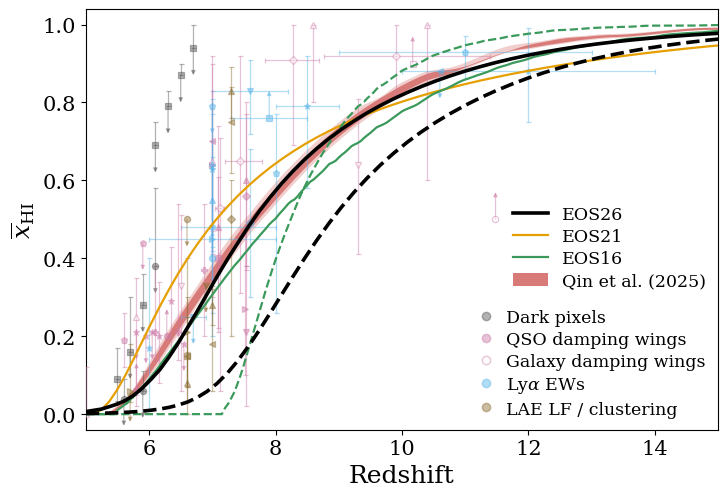

In [5]:
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.fill_between(qin["z"], qin["lo95"], qin["hi95"], color=QIN25_COLOR, alpha=0.25, lw=0, zorder=1)
ax.fill_between(qin["z"], qin["lo68"], qin["hi68"], color=QIN25_COLOR, alpha=0.6, lw=0, zorder=1)

for label, (z, x) in models.items():
    ax.plot(z, x, **MODEL_STYLE[label])
# one legend entry per EOS release (solid = fiducial run, dashed = variant: said in the caption)
model_handles = [Line2D([], [], color=EOS_COLORS[k], lw=MODEL_STYLE[m]["lw"])
                 for k, m in (("EOS26", "EOS26"), ("EOS21", "EOS21"), ("EOS16", "EOS16 faint galaxies"))]
model_handles.append((Patch(color=QIN25_COLOR, alpha=0.25, lw=0), Patch(color=QIN25_COLOR, alpha=0.6, lw=0)))
model_labels = ["EOS26", "EOS21", "EOS16", "Qin et al. (2025)"]

for r in obs:
    _, color, filled = METHODS[r["method"]]
    draw_point(ax, r, color, style[r["dataset"]], filled)

ax.set_xlim(*ZLIM)
ax.set_ylim(-0.04, 1.04)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_xlabel("Redshift")
ax.set_ylabel(r"$\overline{x}_{\rm HI}$")
method_handles = [Line2D([], [], ls="none", marker="o", ms=6, color=c, mec=c, mfc=c if f else "white", label=l,
                         alpha=DATA_ALPHA)
                  for l, c, f in METHODS.values()]
# both legends inside the axes, stacked in the empty lower-right corner (data below, models above)
fig.tight_layout()
leg_data = ax.legend(handles=method_handles, loc="lower right", frameon=False, handletextpad=0.2,
                     borderaxespad=0.3, labelspacing=0.3)
ax.add_artist(leg_data)
fig.canvas.draw()
y1 = leg_data.get_window_extent().transformed(ax.transAxes.inverted()).y1
ax.legend(model_handles, model_labels, loc="lower right", bbox_to_anchor=(1, y1), frameon=False,
          handlelength=2.0, borderaxespad=0.3, labelspacing=0.3)
for ext in ("pdf", "png"):
    fig.savefig(OUT.with_suffix(f".{ext}"), dpi=200, bbox_inches="tight")
print("saved", OUT.with_suffix(".pdf"), "and .png")
if eos26_note:
    print("For the caption:", eos26_note)
plt.show()

Key: one entry per dataset (not for the paper), to check the markers and to write the caption.

In [6]:
if KEY_FIGURE:
    handles = []
    for m, (label, color, filled) in METHODS.items():
        for d in dict.fromkeys(r["dataset"] for r in obs if r["method"] == m):
            new = not any(r["in_qin25"] for r in obs if r["dataset"] == d)
            handles.append(Line2D([], [], ls="none", marker=style[d], ms=5, color=color, mec=color,
                                  mfc=color if filled else "white", label=d + (" (new)" if new else "")))
    fk = plt.figure(figsize=(7, 3.2))
    fk.legend(handles=handles, loc="center", ncol=4, frameon=False, fontsize=9)
    fk.savefig(OUT.parent / (OUT.name + "_key.png"), dpi=150, bbox_inches="tight")
    plt.show()

<Figure size 700x320 with 0 Axes>

## Numbers for the text

In [7]:
LEVELS = [0.9, 0.75, 0.5, 0.25, 0.1, 0.01]
print(f"{'redshift at x_HI =':34s}" + "".join(f"{l:>12}" for l in LEVELS) + "   Dz(0.9-0.1)")
cells = []
for l in LEVELS:
    a, b = z_at_xhi(qin["z"], qin["hi68"], l), z_at_xhi(qin["z"], qin["lo68"], l)
    cells.append(f"{a:.2f}-{b:.2f}")
print(f"{'Qin+25, 68% (digitized)':34s}" + "".join(f"{c:>12}" for c in cells))
for label, (z, x) in models.items():
    zs = [z_at_xhi(z, x, l) for l in LEVELS]
    print(f"{LABELS.get(label, label):34s}" + "".join(f"{v:12.2f}" for v in zs) + f"{zs[0] - zs[4]:12.2f}")

# citation keys per method, for the caption (and keys not yet in refs.bib)
bib = set(re.findall(r"@\w+\{([^,]+),", BIB_FILE.read_text())) if BIB_FILE.exists() else None
print()
for m, (label, _, _) in METHODS.items():
    keys = list(dict.fromkeys(r["key"] for r in obs if r["method"] == m))
    print(f"{label}: \\citealt{{{','.join(keys)}}}")
if bib is not None:
    missing = [k for k in dict.fromkeys(r["key"] for r in obs) if k not in bib]
    print("\nnot in refs.bib:", ", ".join(missing) if missing else "none")

redshift at x_HI =                         0.9        0.75         0.5        0.25         0.1        0.01   Dz(0.9-0.1)
Qin+25, 68% (digitized)            11.11-11.14   9.09-9.28   7.57-7.72   6.47-6.60   5.90-5.98   5.40-5.47
EOS26 fiducial                           11.43        9.22        7.65        6.71        6.09        5.13        5.33
EOS26 early EoR                          12.74       10.54        8.89        7.88        7.21        6.03        5.54
EOS21                                    12.67        9.15        7.06        6.09        5.63        5.23        7.05
EOS16 faint galaxies                     11.73        9.77        7.99        6.74        6.05        5.50        5.68
EOS16 bright galaxies                    10.26        9.09        8.24        7.72        7.45        7.18        2.81

Dark pixels: \citealt{McGreer15,Jin23}
QSO damping wings: \citealt{MesingerHaiman04,Greig17a,Banados18,Davies18,Greig19,Wang20,Greig22,Spina24,Zhu24,Greig24b,Durovcikova24}
Gal